In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


df_model = pd.read_excel("Cleaned_FINAL.xlsx")

In [3]:
summary = pd.DataFrame({
    "Data Type": df_model.dtypes.astype(str),
    "Non-Null": df_model.notna().sum(),
    "Null": df_model.isna().sum(),
    "Null (%)": (df_model.isna().mean() * 100).round(2),
    "Unique Values": df_model.nunique()
})

display(summary)

,Data Type,Non-Null,Null,Null (%),Unique Values
MaHoSo_TS,str,21478,0,0.00,21476
DiemTongCong,float64,20690,788,3.67,176
NamTotNghiep,float64,20770,708,3.30,59
IDSinhVien,int64,21478,0,0.00,21478
MaSinhVien,int64,21478,0,0.00,21478
Ten,str,21478,0,0.00,779
GioiTinh,bool,21478,0,0.00,2
NgaySinh2,str,21478,0,0.00,4460
KhoaHoc,int64,21478,0,0.00,7
IDNganh,int64,21478,0,0.00,81


Kích thước dữ liệu: (21478, 39)
Số dòng trùng: 0
Số IDSinhVien trùng: 0


,SoLuong,TyLe_%
NhomTrangThai,,
Đã tốt nghiệp,12207,56.83
Thôi học / Tạm ngưng học,9271,43.17


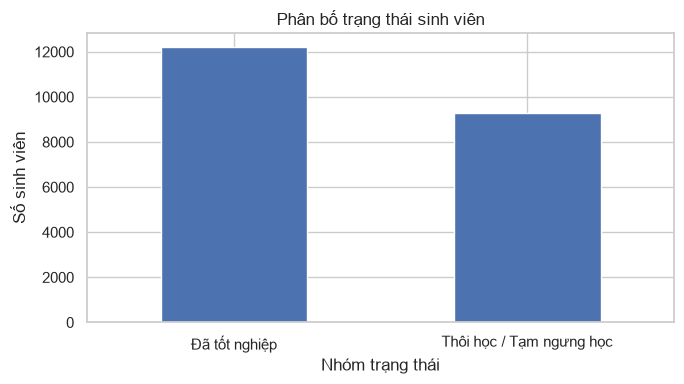

In [4]:
print("Kích thước dữ liệu:", df_model.shape)
print("Số dòng trùng:", df_model.duplicated().sum())
print("Số IDSinhVien trùng:",
      df_model["IDSinhVien"].duplicated().sum()
      if "IDSinhVien" in df_model.columns else "Không có cột ID")

# Phân bố target
target_summary = (
    df_model["NhomTrangThai"]
    .value_counts()
    .sort_index()
    .rename(index={
        1: "Đã tốt nghiệp",
        2: "Thôi học / Tạm ngưng học"
    })
    .to_frame("SoLuong")
)

target_summary["TyLe_%"] = (
    target_summary["SoLuong"] / len(df_model) * 100
).round(2)

display(target_summary)

# Biểu đồ phân bố target
target_summary["SoLuong"].plot(
    kind="bar",
    figsize=(7, 4),
    rot=0
)

plt.title("Phân bố trạng thái sinh viên")
plt.xlabel("Nhóm trạng thái")
plt.ylabel("Số sinh viên")
plt.tight_layout()
plt.show()

In [5]:
numeric_cols = [
    "Tuoi",
    "DiemTongCong",
    "DiemTBHocLuc_HK1",
    "DiemTBTinChi_HK1",
    "STCDangKyHocKy_HK1",
    "SoTCKhongDat_HK1"
]

numeric_cols = [
    c for c in numeric_cols
    if c in df_model.columns
]

group_summary = (
    df_model.groupby("NhomTrangThai")[numeric_cols]
    .agg(["mean", "median", "std"])
    .round(2)
)

display(group_summary)

Tuoi              DiemTongCong              DiemTBHocLuc_HK1  \
                mean median   std         mean median   std             mean   
NhomTrangThai                                                                  
1              17.74   18.0  3.60         7.07    7.1  0.82             6.65   
2              17.28   18.0  2.17         6.73    6.8  0.85             3.86   

                           DiemTBTinChi_HK1              STCDangKyHocKy_HK1  \
              median   std             mean median   std               mean   
NhomTrangThai                                                                 
1               6.69  1.05             2.38    2.4  0.65              15.62   
2               4.40  2.45             1.13    1.1  0.98              15.46   

                           SoTCKhongDat_HK1               
              median   std             mean median   std  
NhomTrangThai                                             
1               14.0  4.70             0.42    0.0  1.30  
2               14.0  4.75             6.00    4.0  5.88

<Figure size 1100x600 with 0 Axes>

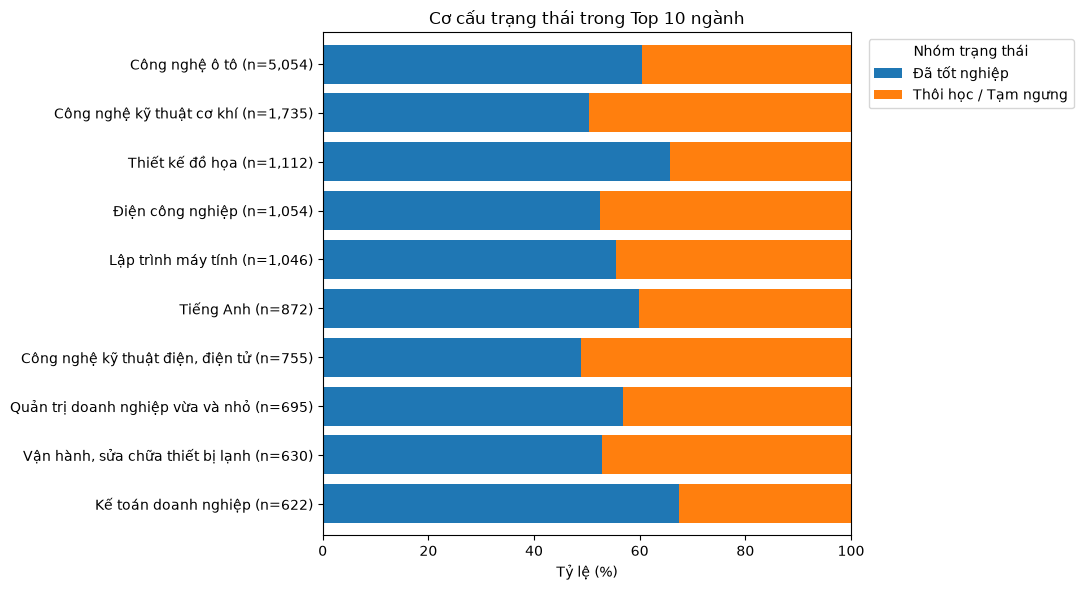

<Figure size 1100x600 with 0 Axes>

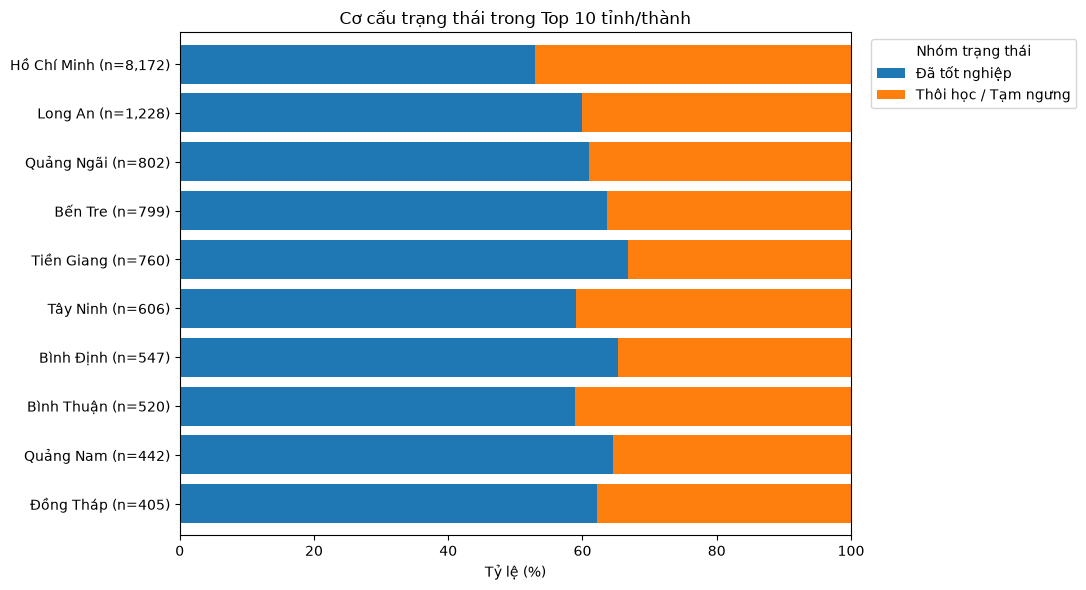

<Figure size 1100x600 with 0 Axes>

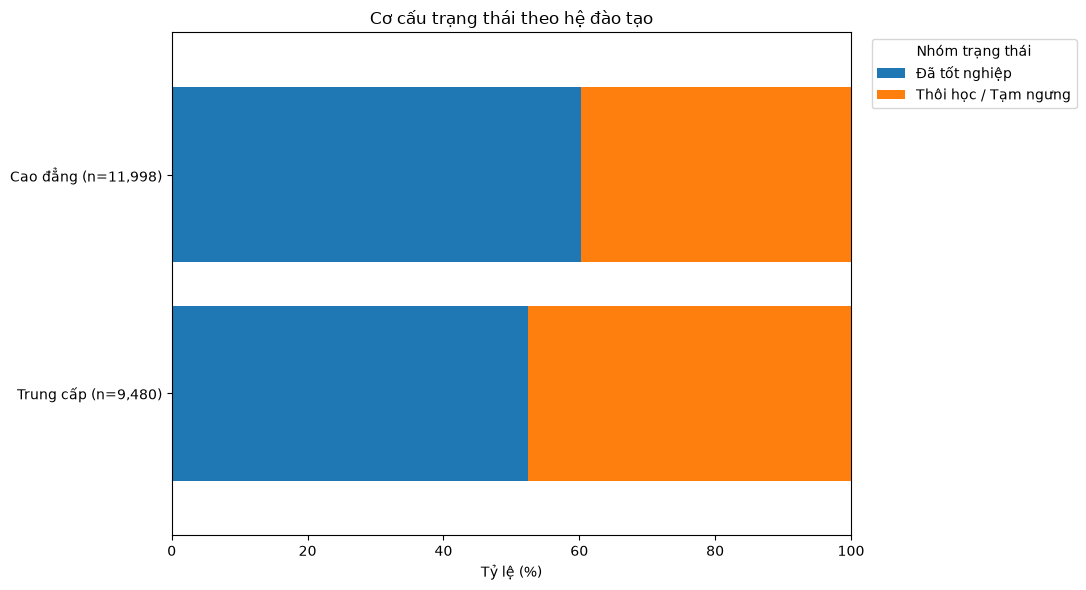

<Figure size 1100x600 with 0 Axes>

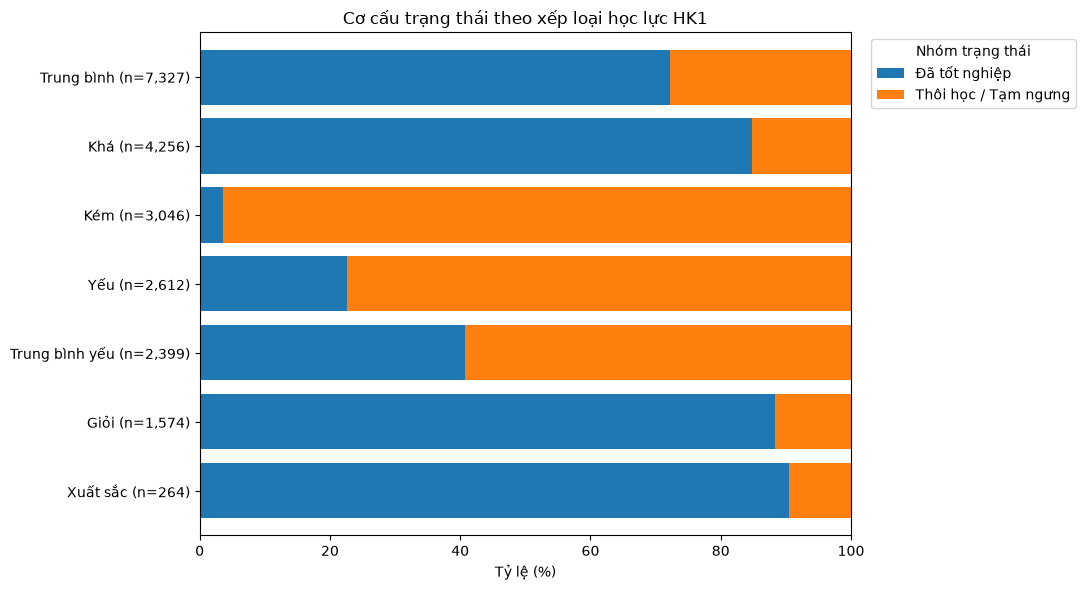

<Figure size 1100x600 with 0 Axes>

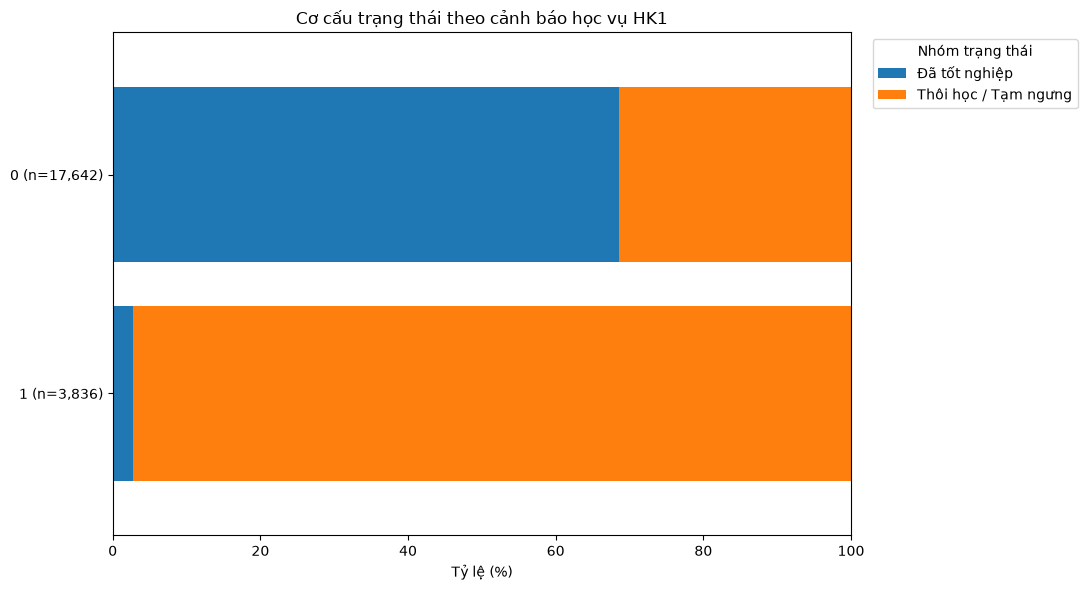

<Figure size 1100x600 with 0 Axes>

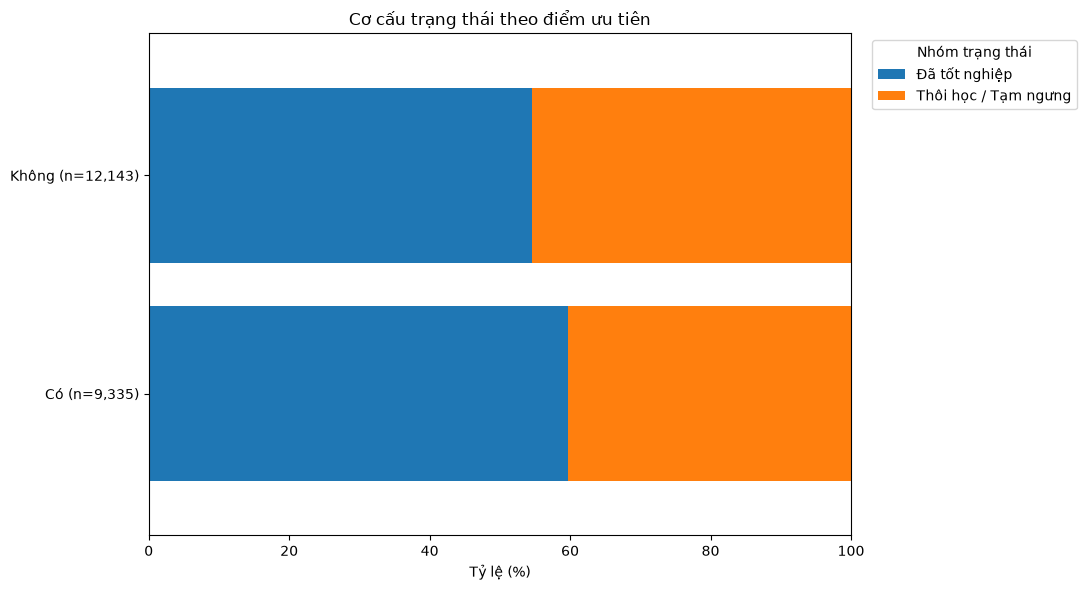

<Figure size 1100x600 with 0 Axes>

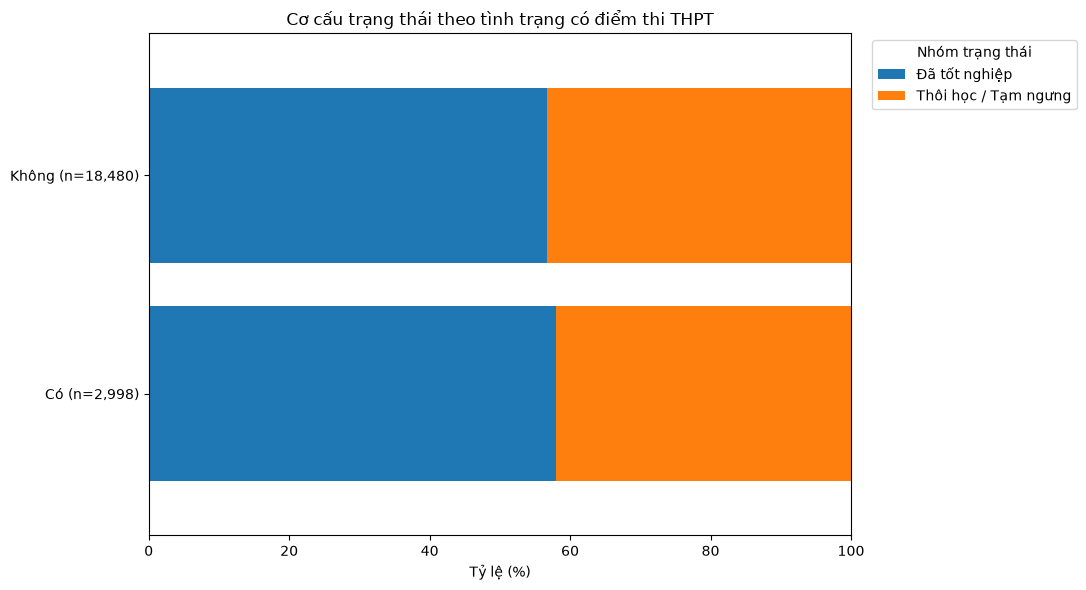

<Figure size 1100x600 with 0 Axes>

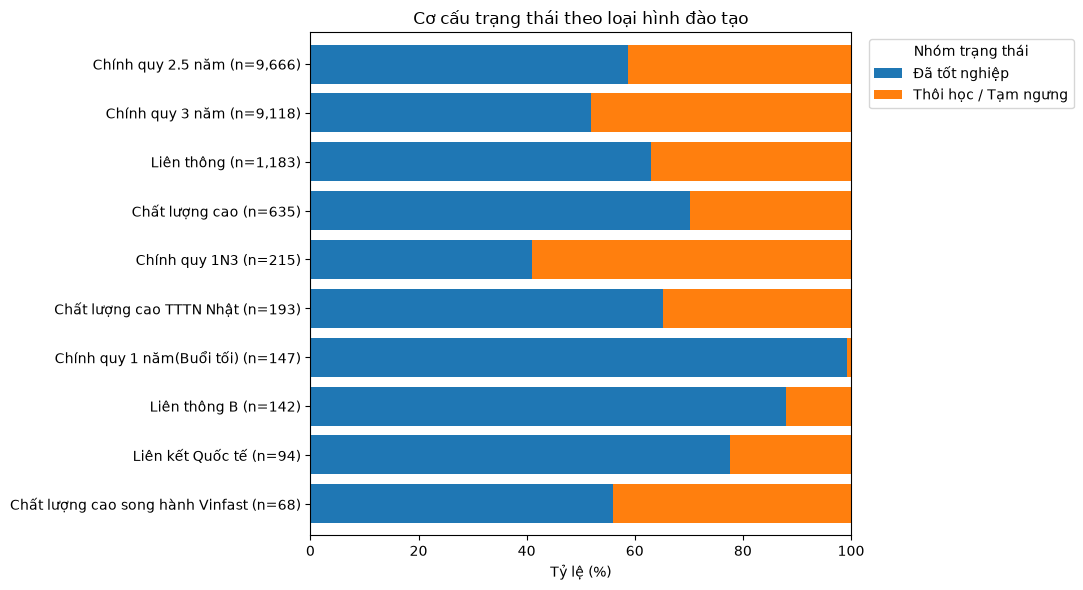

<Figure size 1100x600 with 0 Axes>

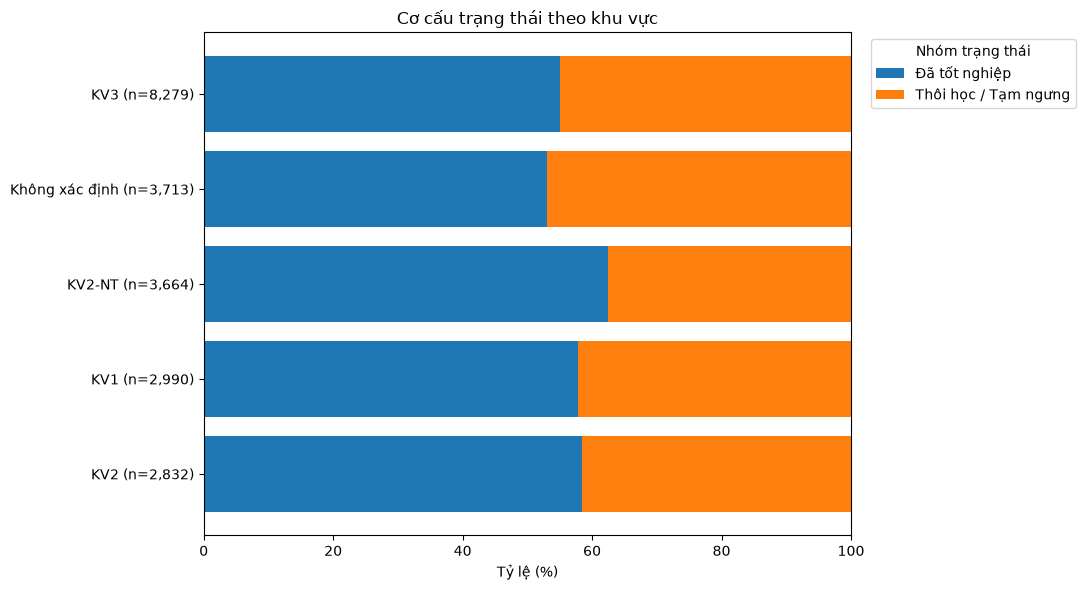

<Figure size 1100x600 with 0 Axes>

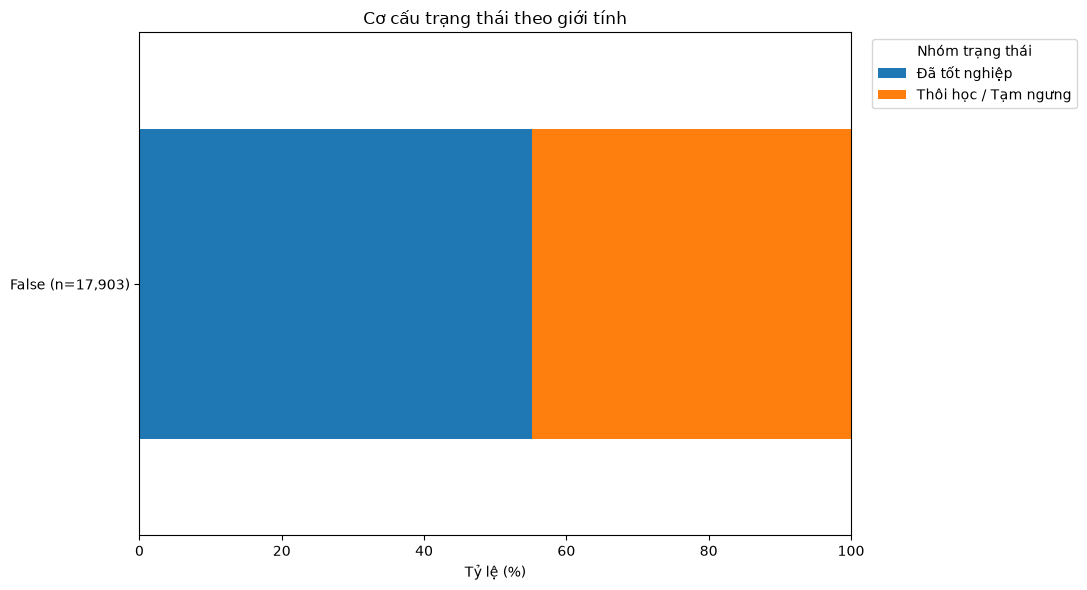

In [49]:
import pandas as pd
import matplotlib.pyplot as plt

# Chuẩn bị dữ liệu
plot_df = df.copy()

plot_df["NhomTrangThai"] = pd.to_numeric(
    plot_df["NhomTrangThai"], errors="coerce"
)

# Chỉ lấy hai nhóm trạng thái hợp lệ
plot_df = plot_df[
    plot_df["NhomTrangThai"].isin([1, 2])
].copy()

status_labels = {
    1: "Đã tốt nghiệp",
    2: "Thôi học / Tạm ngưng"
}

plot_df["NhomTrangThai"] = plot_df["NhomTrangThai"].map(status_labels)


def plot_status_distribution(data, category_col, title, top_n=10):
    # Chọn Top N theo tổng số sinh viên
    top_categories = (
        data[category_col]
        .dropna()
        .value_counts()
        .head(top_n)
        .index
    )

    sub = data[data[category_col].isin(top_categories)]

    # Tính tỷ lệ từng nhóm trạng thái trong mỗi ngành/tỉnh
    crosstab = pd.crosstab(
        sub[category_col],
        sub["NhomTrangThai"],
        normalize="index"
    ) * 100

    # Đảm bảo thứ tự nhóm nhất quán
    crosstab = crosstab.reindex(
        columns=["Đã tốt nghiệp", "Thôi học / Tạm ngưng"],
        fill_value=0
    )

    # Sắp xếp để dễ đọc biểu đồ
    crosstab = crosstab.loc[
        sub[category_col].value_counts().reindex(top_categories).sort_values().index
    ]

    # Thêm cỡ mẫu vào nhãn
    counts = sub[category_col].value_counts()
    labels = [
        f"{category} (n={counts[category]:,})"
        for category in crosstab.index
    ]

    ax = crosstab.copy()
    ax.index = labels

    ax.plot if False else None  # Không thay đổi dữ liệu

    ax.plot if False else None
    ax = ax

    plt.figure(figsize=(11, 6))
    ax_plot = crosstab.copy()
    ax_plot.index = labels
    ax_plot.plot(
        kind="barh",
        stacked=True,
        figsize=(11, 6),
        width=0.8
    )

    plt.title(title)
    plt.xlabel("Tỷ lệ (%)")
    plt.ylabel("")
    plt.xlim(0, 100)
    plt.legend(title="Nhóm trạng thái", bbox_to_anchor=(1.02, 1), loc="upper left")
    plt.tight_layout()
    plt.show()


# Biểu đồ 1: Top 10 ngành
plot_status_distribution(
    plot_df,
    "TenNganh",
    "Cơ cấu trạng thái trong Top 10 ngành"
)

# Biểu đồ 2: Top 10 tỉnh/thành
plot_status_distribution(
    plot_df,
    "TenTinh",
    "Cơ cấu trạng thái trong Top 10 tỉnh/thành"
)

# Biểu đồ 3: Hệ đào tạo
plot_status_distribution(
    plot_df,
    "TenHeDaoTao",
    "Cơ cấu trạng thái theo hệ đào tạo",
    top_n=10
)

# Biểu đồ 4: Xếp loại học lực HK1
plot_status_distribution(
    plot_df,
    "XepLoaiHocLuc_HK1",
    "Cơ cấu trạng thái theo xếp loại học lực HK1",
    top_n=10
)

# Biểu đồ 5: Cảnh báo học vụ HK1
plot_status_distribution(
    plot_df,
    "CanhCaoHocVu_HK1",
    "Cơ cấu trạng thái theo cảnh báo học vụ HK1"
)

# Biểu đồ 6: Có điểm ưu tiên hay không
plot_status_distribution(
    plot_df,
    "CoDiemUuTien",
    "Cơ cấu trạng thái theo điểm ưu tiên"
)

# Biểu đồ 7: Có dữ liệu điểm thi THPT hay không
plot_status_distribution(
    plot_df,
    "CoDiemThiTHPT",
    "Cơ cấu trạng thái theo tình trạng có điểm thi THPT"
)

# Biểu đồ 8: Theo loại hình đào tạo
plot_status_distribution(
    plot_df,
    "TenLoaiHinhDT",
    "Cơ cấu trạng thái theo loại hình đào tạo"
)

# Biểu đồ 9: Theo khu vực
plot_status_distribution(
    plot_df,
    "TenKhuVuc",
    "Cơ cấu trạng thái theo khu vực"
)

plot_status_distribution(
    plot_df,
    "GioiTinh",
    "Cơ cấu trạng thái theo giới tính"
)

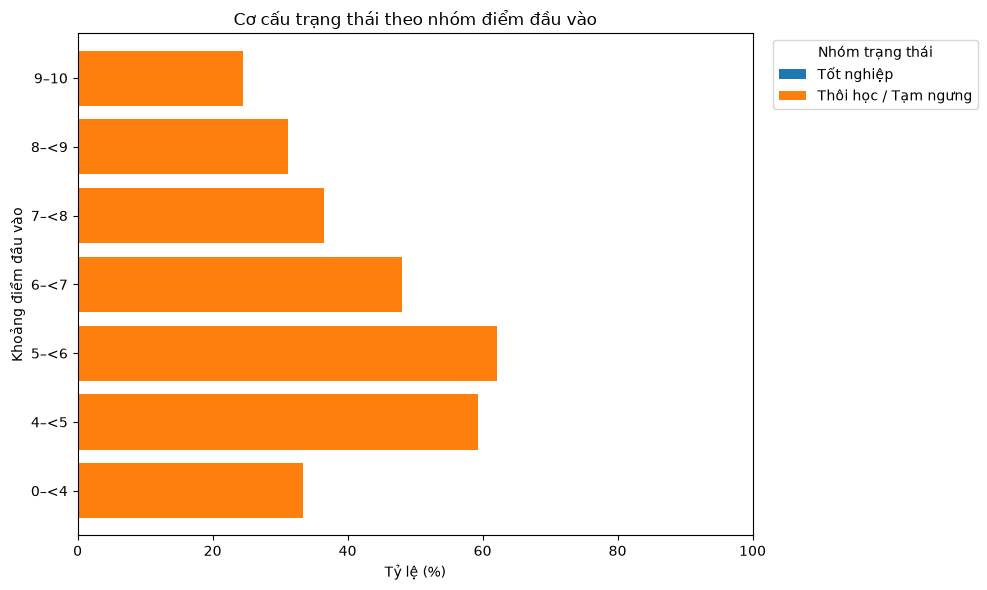

NhomTrangThai,Thôi học / Tạm ngưng,Đã tốt nghiệp
NhomDiemDauVao,,
0–<4,2,4
4–<5,32,22
5–<6,1358,828
6–<7,3771,4079
7–<8,3010,5235
8–<9,694,1537
9–10,29,89


In [48]:
# Chuẩn bị dữ liệu
score_df = plot_df.copy()

score_df["DiemTongCong"] = pd.to_numeric(
    score_df["DiemTongCong"], errors="coerce"
)

score_df = score_df[
    score_df["DiemTongCong"].between(0, 10)
    & (score_df["DiemTongCong"] > 0)
].copy()

# Chia nhóm điểm
bins = [0, 4, 5, 6, 7, 8, 9, 10.001]
labels = [
    "0–<4", "4–<5", "5–<6", "6–<7",
    "7–<8", "8–<9", "9–10"
]

score_df["NhomDiemDauVao"] = pd.cut(
    score_df["DiemTongCong"],
    bins=bins,
    labels=labels,
    right=False
)

# Tính tỷ lệ từng nhóm trạng thái trong mỗi khoảng điểm
score_crosstab = pd.crosstab(
    score_df["NhomDiemDauVao"],
    score_df["NhomTrangThai"],
    normalize="index"
).mul(100)

# Bảo đảm thứ tự nhóm điểm và trạng thái
status_order = ["Tốt nghiệp", "Thôi học / Tạm ngưng"]

score_crosstab = score_crosstab.reindex(
    index=labels,
    columns=status_order,
    fill_value=0
).fillna(0)

# Vẽ biểu đồ thanh ngang chồng 100%
ax = score_crosstab.plot(
    kind="barh",
    stacked=True,
    figsize=(10, 6),
    width=0.8
)

ax.set_title("Cơ cấu trạng thái theo nhóm điểm đầu vào")
ax.set_xlabel("Tỷ lệ (%)")
ax.set_ylabel("Khoảng điểm đầu vào")
ax.set_xlim(0, 100)
ax.legend(
    title="Nhóm trạng thái",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

plt.tight_layout()
plt.show()

# Xem số lượng thực tế trong từng khoảng điểm
display(
    score_df.groupby(
        "NhomDiemDauVao",
        observed=False
    )["NhomTrangThai"]
    .value_counts()
    .unstack(fill_value=0)
)

In [6]:
df = df_model.copy()

In [15]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import math

# Tạo bản dùng riêng cho EDA, không thay đổi df gốc
eda = df.copy()

# Chuyển các biến điểm và tín chỉ về numeric
numeric_cols = [
    "DiemTongCong",
    "DiemTBHocLuc_HK1",
    "DiemTBHocLuc_HK2",
    "DiemTBTinChi_HK1",
    "DiemTBTinChi_HK2",
    "STCDangKyHocKy_HK1",
    "STCDangKyHocKy_HK2",
    "SoTCKhongDat_HK1",
    "SoTCKhongDat_HK2",
    "CanhCaoHocVu_HK1",
    "CanhCaoHocVu_HK2"
]

for col in numeric_cols:
    if col in eda.columns:
        eda[col] = pd.to_numeric(eda[col], errors="coerce")

# Gộp trạng thái thành 2 nhóm để so sánh
status_mapping = {
    "Đã tốt nghiệp": "Tốt nghiệp",
    "Thôi học": "Thôi học / Tạm ngưng",
    "Tạm ngưng học": "Thôi học / Tạm ngưng"
}

eda["NhomKetQua"] = eda["TenTrangThai"].map(status_mapping)

print("Số dòng:", len(eda))
print("Số sinh viên có trạng thái phù hợp:",
      eda["NhomKetQua"].notna().sum())

Số dòng: 21478
Số sinh viên có trạng thái phù hợp: 21478


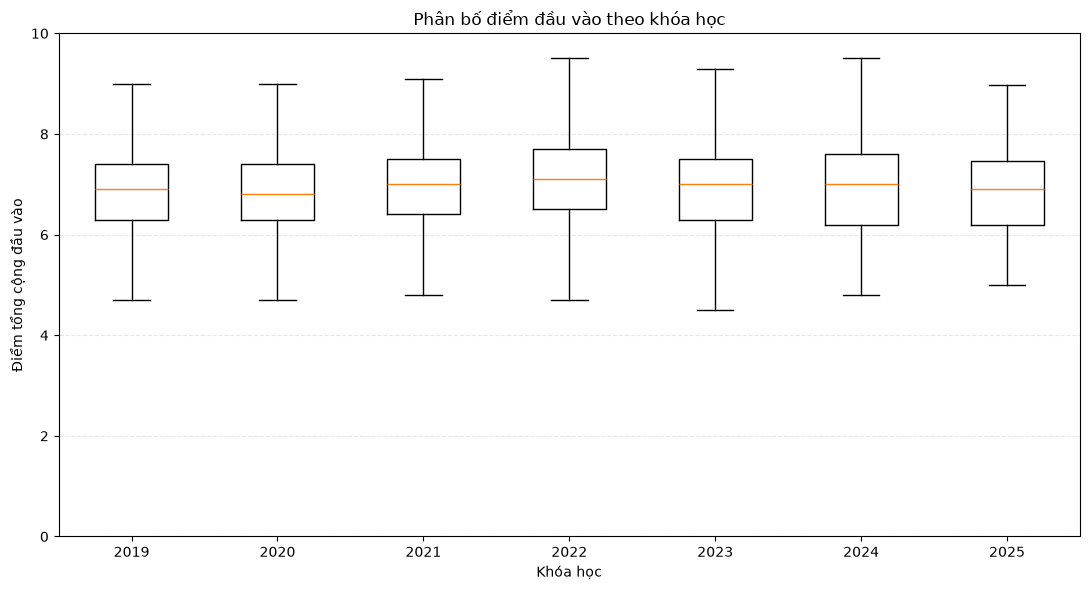

In [39]:
# Chuẩn bị dữ liệu
plot_df = df.copy()

plot_df["KhoaHoc_num"] = pd.to_numeric(
    plot_df["KhoaHoc"], errors="coerce"
)

plot_df["DiemTongCong"] = pd.to_numeric(
    plot_df["DiemTongCong"], errors="coerce"
)

# Chỉ giữ điểm đầu vào hợp lệ
input_df = plot_df[
    plot_df["DiemTongCong"].between(0, 10, inclusive="both")
    & (plot_df["DiemTongCong"] > 0)
].copy()

years_input = sorted(input_df["KhoaHoc_num"].dropna().unique())

plot_data = [
    input_df.loc[
        input_df["KhoaHoc_num"] == year, "DiemTongCong"
    ].dropna().to_numpy()
    for year in years_input
]

plt.figure(figsize=(11, 6))
plt.boxplot(
    plot_data,
    tick_labels=[str(int(y)) for y in years_input],
    showfliers=False
)

plt.title("Phân bố điểm đầu vào theo khóa học")
plt.xlabel("Khóa học")
plt.ylabel("Điểm tổng cộng đầu vào")
plt.ylim(0, 10)
plt.grid(axis="y", linestyle="--", alpha=0.3)
plt.tight_layout()
plt.show()

In [22]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

def plot_group_boxplot(
    data,
    category_col,
    value_col,
    title,
    xlabel,
    ylabel,
    top_n=None,
    min_count=30,
    horizontal=True,
    exclude_unknown=False
):
    temp = data[[category_col, value_col]].copy()

    temp[value_col] = pd.to_numeric(
        temp[value_col], errors="coerce"
    )
    temp = temp.dropna(subset=[category_col, value_col])

    if exclude_unknown:
        temp = temp[
            temp[category_col].astype(str).str.strip()
            != "Không xác định"
        ]

    # Chỉ giữ nhóm có đủ quan sát
    counts = temp[category_col].value_counts()
    valid_groups = counts[counts >= min_count]

    if top_n is not None:
        valid_groups = valid_groups.head(top_n)

    temp = temp[
        temp[category_col].isin(valid_groups.index)
    ]

    if temp.empty:
        print(f"Không đủ dữ liệu cho biểu đồ: {title}")
        return

    # Sắp xếp nhóm theo median
    medians = temp.groupby(category_col)[value_col].median()
    group_order = medians.sort_values().index.tolist()

    plot_data = [
        temp.loc[temp[category_col] == group, value_col].values
        for group in group_order
    ]

    # Hiển thị cỡ mẫu mỗi nhóm
    labels = [
        f"{group} (n={len(values):,})"
        for group, values in zip(group_order, plot_data)
    ]

    plt.figure(figsize=(
        (12, max(6, len(labels) * 0.42))
        if horizontal else (10, 5)
    ))

    if horizontal:
        plt.boxplot(
            plot_data,
            orientation="horizontal",
            tick_labels=labels,
            showfliers=False
        )
    else:
        plt.boxplot(
            plot_data,
            orientation="vertical",
            tick_labels=labels,
            showfliers=False
        )

    plt.title(title)
    plt.xlabel(xlabel if horizontal else ylabel)
    plt.ylabel(ylabel if horizontal else xlabel)

    if horizontal:
        plt.ylabel("")
    else:
        plt.xticks(rotation=30, ha="right")

    plt.tight_layout()
    plt.show()

    # Bảng thống kê đi kèm
    stats = (
        temp.groupby(category_col)[value_col]
        .agg(["count", "mean", "median", "std"])
        .round(2)
        .loc[group_order]
    )

    display(stats)

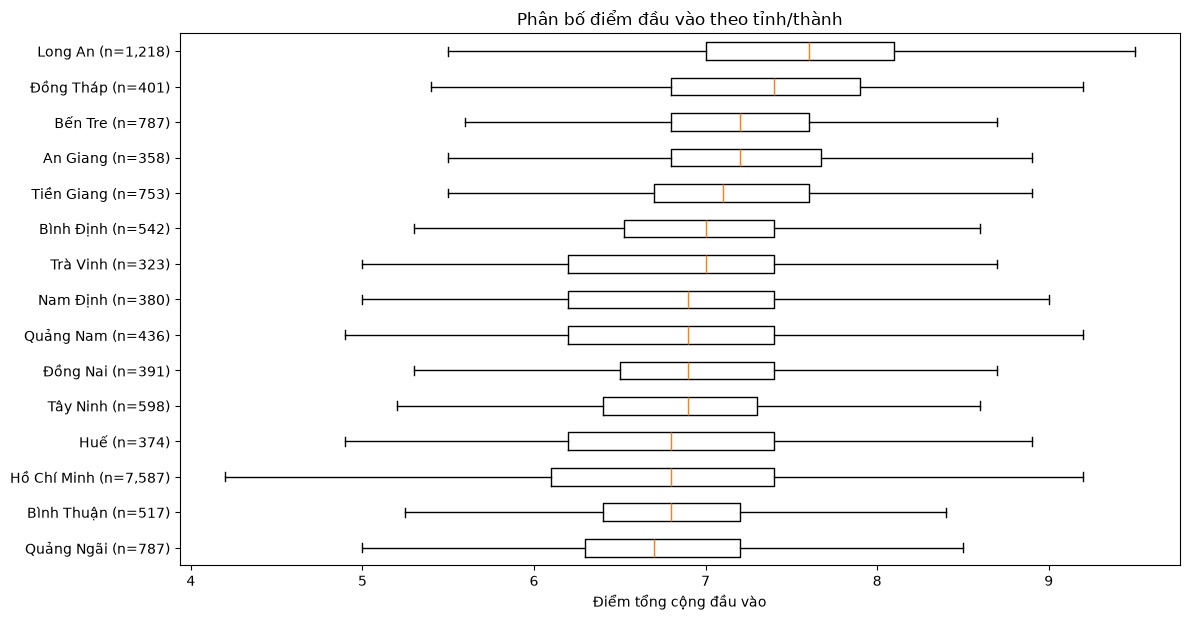

,count,mean,median,std
TenTinh,,,,
Quảng Ngãi,787,6.74,6.7,0.73
Bình Thuận,517,6.79,6.8,0.67
Hồ Chí Minh,7587,6.80,6.8,0.89
Huế,374,6.79,6.8,0.83
Tây Ninh,598,6.86,6.9,0.65
Đồng Nai,391,6.93,6.9,0.74
Quảng Nam,436,6.82,6.9,0.81
Nam Định,380,6.87,6.9,0.84
Trà Vinh,323,6.85,7.0,0.83


In [23]:
plot_group_boxplot(
    data=df,
    category_col="TenTinh",
    value_col="DiemTongCong",
    title="Phân bố điểm đầu vào theo tỉnh/thành",
    xlabel="Điểm tổng cộng đầu vào",
    ylabel="Tỉnh/thành",
    top_n=15,
    min_count=30,
    horizontal=True,
    exclude_unknown=True
)

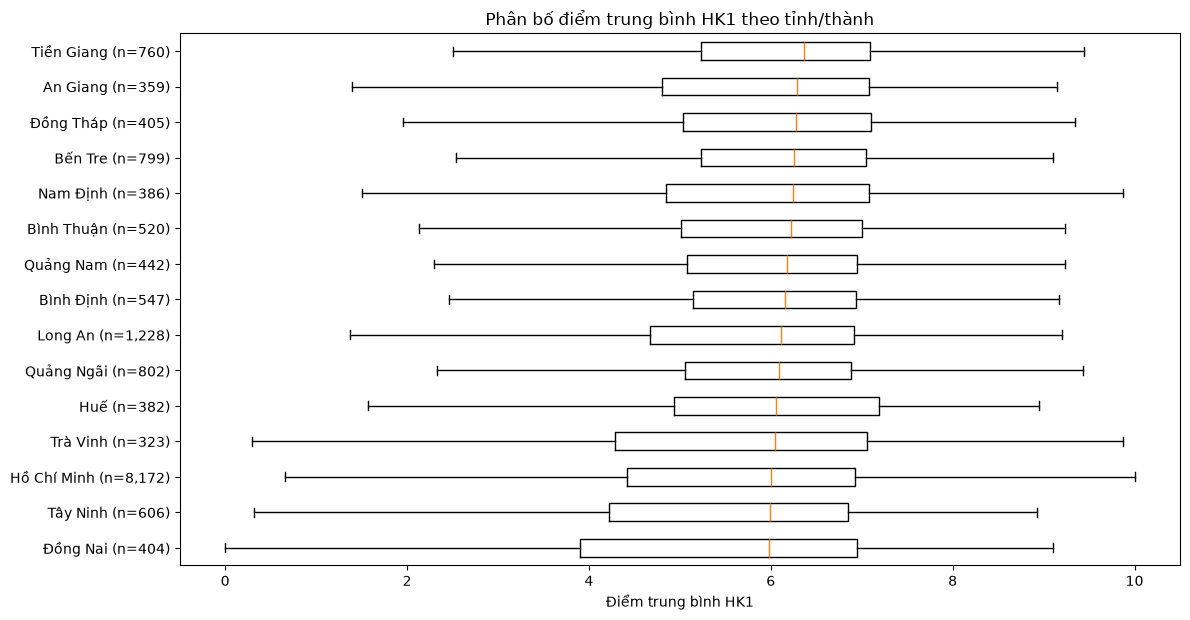

,count,mean,median,std
TenTinh,,,,
Đồng Nai,404,5.17,5.98,2.51
Tây Ninh,606,5.22,6.00,2.36
Hồ Chí Minh,8172,5.31,6.00,2.34
Trà Vinh,323,5.38,6.05,2.31
Huế,382,5.58,6.06,2.14
Quảng Ngãi,802,5.58,6.08,2.01
Long An,1228,5.41,6.11,2.25
Bình Định,547,5.55,6.16,2.16
Quảng Nam,442,5.66,6.18,2.01


In [24]:
plot_group_boxplot(
    data=df,
    category_col="TenTinh",
    value_col="DiemTBHocLuc_HK1",
    title="Phân bố điểm trung bình HK1 theo tỉnh/thành",
    xlabel="Điểm trung bình HK1",
    ylabel="Tỉnh/thành",
    top_n=15,
    min_count=30,
    horizontal=True,
    exclude_unknown=True
)

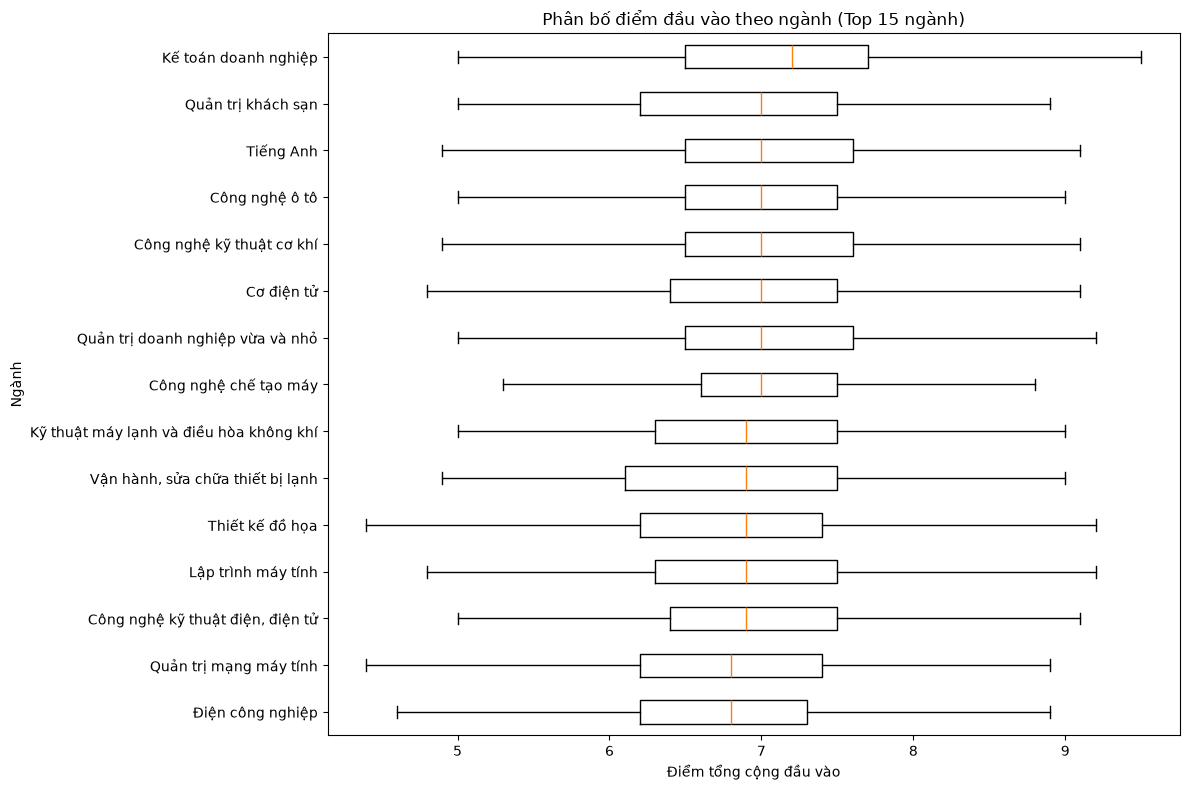

In [28]:
# Chuẩn bị dữ liệu
temp = df.dropna(subset=["TenNganh", "DiemTongCong"]).copy()

# Điểm đầu vào hợp lệ: lớn hơn 0 và không vượt thang điểm 10
temp = temp[
    temp["DiemTongCong"].between(0, 10)
    & (temp["DiemTongCong"] > 0)
]

# Chọn 15 ngành có nhiều quan sát hợp lệ nhất, tối thiểu 30 SV
major_counts = temp["TenNganh"].value_counts()
selected_majors = (
    major_counts[major_counts >= 30]
    .head(15)
    .index
    .tolist()
)

temp = temp[temp["TenNganh"].isin(selected_majors)]

# Sắp xếp ngành theo median điểm đầu vào
major_order = (
    temp.groupby("TenNganh")["DiemTongCong"]
    .median()
    .sort_values()
    .index
    .tolist()
)

plot_data = [
    temp.loc[temp["TenNganh"] == major, "DiemTongCong"].values
    for major in major_order
]

# Vẽ boxplot
plt.figure(figsize=(12, 8))
plt.boxplot(
    plot_data,
    orientation="horizontal",
    tick_labels=major_order,
    showfliers=False
)

plt.title("Phân bố điểm đầu vào theo ngành (Top 15 ngành)")
plt.xlabel("Điểm tổng cộng đầu vào")
plt.ylabel("Ngành")
plt.tight_layout()
plt.show()

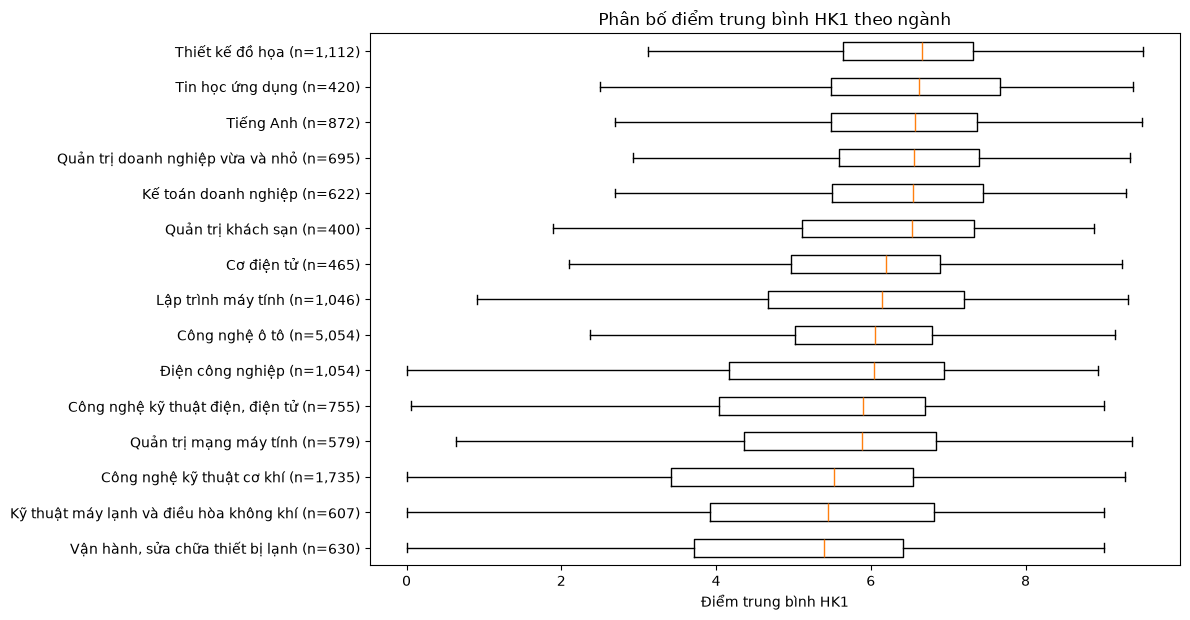

,count,mean,median,std
TenNganh,,,,
"Vận hành, sửa chữa thiết bị lạnh",630,4.90,5.39,2.18
Kỹ thuật máy lạnh và điều hòa không khí,607,5.07,5.45,2.23
Công nghệ kỹ thuật cơ khí,1735,4.82,5.52,2.34
Quản trị mạng máy tính,579,5.20,5.88,2.45
"Công nghệ kỹ thuật điện, điện tử",755,5.16,5.90,2.22
Điện công nghiệp,1054,5.30,6.04,2.31
Công nghệ ô tô,5054,5.42,6.05,2.10
Lập trình máy tính,1046,5.57,6.15,2.30
Cơ điện tử,465,5.63,6.20,2.03


In [25]:
plot_group_boxplot(
    data=df,
    category_col="TenNganh",
    value_col="DiemTBHocLuc_HK1",
    title="Phân bố điểm trung bình HK1 theo ngành",
    xlabel="Điểm trung bình HK1",
    ylabel="Ngành",
    top_n=15,
    min_count=30,
    horizontal=True
)

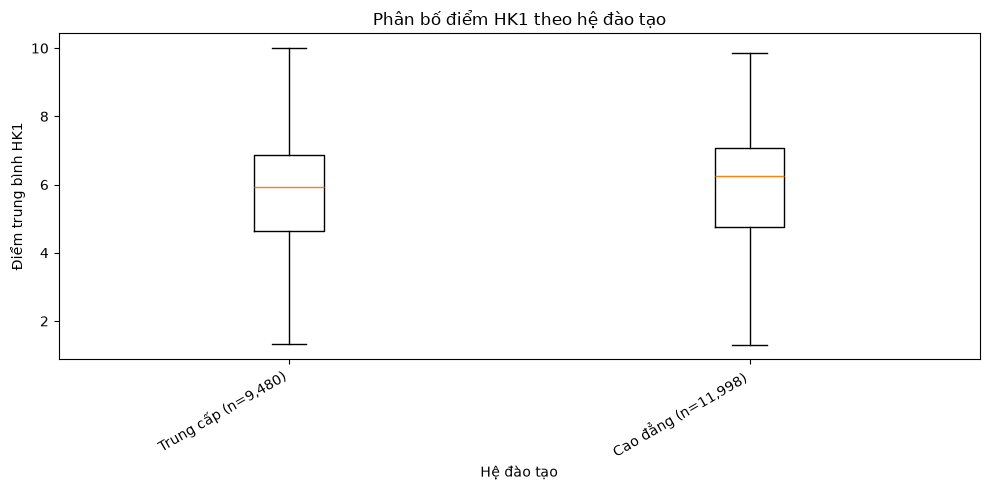

,count,mean,median,std
TenHeDaoTao,,,,
Trung cấp,9480,5.43,5.93,2.11
Cao đẳng,11998,5.46,6.24,2.38


In [26]:
plot_group_boxplot(
    data=df,
    category_col="TenHeDaoTao",
    value_col="DiemTBHocLuc_HK1",
    title="Phân bố điểm HK1 theo hệ đào tạo",
    xlabel="Điểm trung bình HK1",
    ylabel="Hệ đào tạo",
    min_count=30,
    horizontal=False
)

In [29]:
#
#
#

Số sinh viên có điểm cả hai kỳ: 19293
Điểm TB HK1: 5.89
Điểm TB HK2: 5.19
Mức thay đổi HK2 - HK1: -0.69


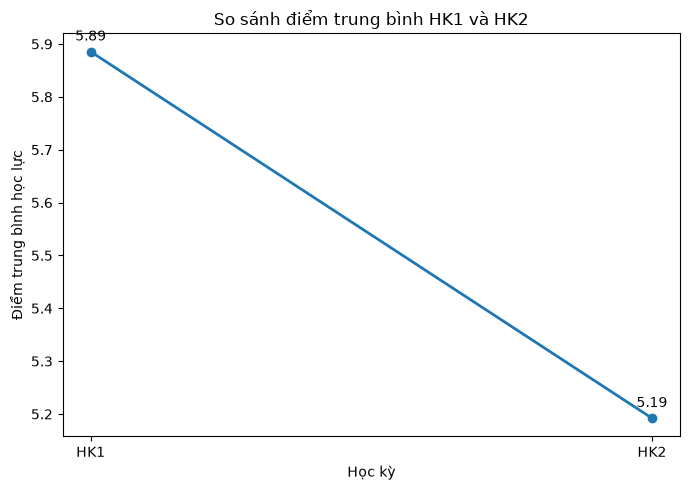

In [30]:
paired = eda.dropna(
    subset=["DiemTBHocLuc_HK1", "DiemTBHocLuc_HK2"]
).copy()

means = [
    paired["DiemTBHocLuc_HK1"].mean(),
    paired["DiemTBHocLuc_HK2"].mean()
]

print("Số sinh viên có điểm cả hai kỳ:", len(paired))
print("Điểm TB HK1:", round(means[0], 2))
print("Điểm TB HK2:", round(means[1], 2))
print("Mức thay đổi HK2 - HK1:", round(means[1] - means[0], 2))

plt.figure(figsize=(7, 5))
plt.plot(
    ["HK1", "HK2"],
    means,
    marker="o",
    linewidth=2
)

for semester, mean in zip(["HK1", "HK2"], means):
    plt.annotate(
        f"{mean:.2f}",
        (semester, mean),
        xytext=(0, 8),
        textcoords="offset points",
        ha="center"
    )

plt.title("So sánh điểm trung bình HK1 và HK2")
plt.ylabel("Điểm trung bình học lực")
plt.xlabel("Học kỳ")
plt.tight_layout()
plt.show()

Số sinh viên có HK1 <= 5 và có cả điểm HK2: 4077
Trung bình HK1: 3.03
Trung bình HK2: 2.1
Thay đổi trung bình: -0.93


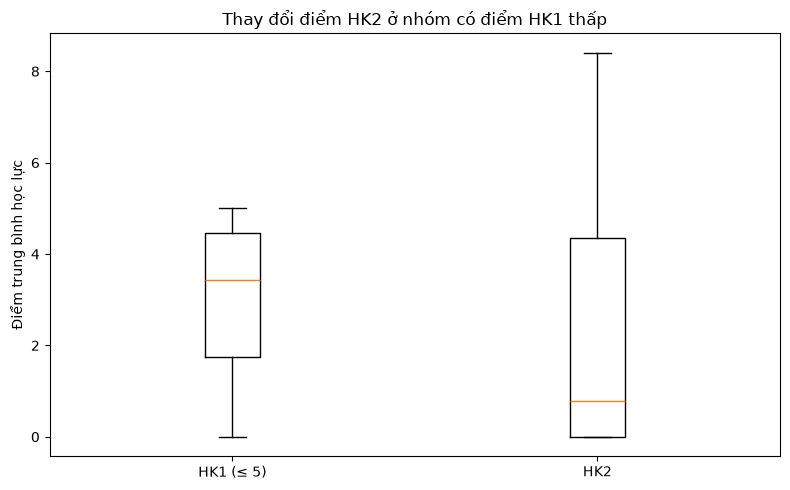

In [32]:
low_score = paired[paired["DiemTBHocLuc_HK1"] <= 5].copy()

low_means = [
    low_score["DiemTBHocLuc_HK1"].mean(),
    low_score["DiemTBHocLuc_HK2"].mean()
]

print("Số sinh viên có HK1 <= 5 và có cả điểm HK2:", len(low_score))
print("Trung bình HK1:", round(low_means[0], 2))
print("Trung bình HK2:", round(low_means[1], 2))
print("Thay đổi trung bình:", round(low_means[1] - low_means[0], 2))

plt.figure(figsize=(8, 5))
plt.boxplot(
    [
        low_score["DiemTBHocLuc_HK1"],
        low_score["DiemTBHocLuc_HK2"]
    ],
    tick_labels=["HK1 (≤ 5)", "HK2"]
)
plt.title("Thay đổi điểm HK2 ở nhóm có điểm HK1 thấp")
plt.ylabel("Điểm trung bình học lực")
plt.tight_layout()
plt.show()

Số sinh viên đủ dữ liệu hai kỳ: 19275


,TyLeKhongDat
HK1,0.121888
HK2,0.226856


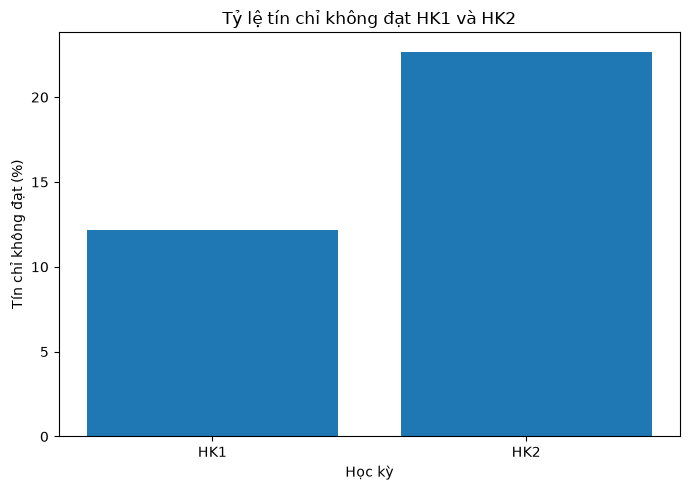

In [33]:
credit_cols = [
    "STCDangKyHocKy_HK1",
    "SoTCKhongDat_HK1",
    "STCDangKyHocKy_HK2",
    "SoTCKhongDat_HK2"
]

credit_pairs = eda.dropna(subset=credit_cols).copy()

credit_pairs = credit_pairs[
    (credit_pairs["STCDangKyHocKy_HK1"] > 0) &
    (credit_pairs["STCDangKyHocKy_HK2"] > 0)
]

rates = {
    "HK1": (
        credit_pairs["SoTCKhongDat_HK1"].sum()
        / credit_pairs["STCDangKyHocKy_HK1"].sum()
    ),
    "HK2": (
        credit_pairs["SoTCKhongDat_HK2"].sum()
        / credit_pairs["STCDangKyHocKy_HK2"].sum()
    )
}

print("Số sinh viên đủ dữ liệu hai kỳ:", len(credit_pairs))
display(pd.Series(rates, name="TyLeKhongDat").to_frame())

plt.figure(figsize=(7, 5))
plt.bar(
    rates.keys(),
    [v * 100 for v in rates.values()]
)
plt.title("Tỷ lệ tín chỉ không đạt HK1 và HK2")
plt.xlabel("Học kỳ")
plt.ylabel("Tín chỉ không đạt (%)")
plt.tight_layout()
plt.show()

In [34]:
#
#
#

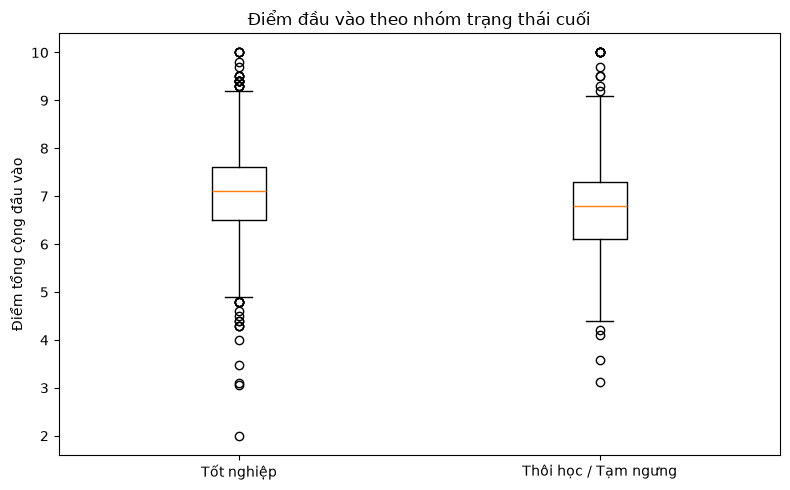

,count,mean,median,std
NhomKetQua,,,,
Thôi học / Tạm ngưng,8896,6.73,6.8,0.85
Tốt nghiệp,11794,7.07,7.1,0.82


In [35]:
status_df = eda.dropna(subset=["NhomKetQua", "DiemTongCong"]).copy()

groups = ["Tốt nghiệp", "Thôi học / Tạm ngưng"]
plot_data = [
    status_df.loc[
        status_df["NhomKetQua"] == group,
        "DiemTongCong"
    ].values
    for group in groups
]

plt.figure(figsize=(8, 5))
plt.boxplot(plot_data, tick_labels=groups)
plt.title("Điểm đầu vào theo nhóm trạng thái cuối")
plt.ylabel("Điểm tổng cộng đầu vào")
plt.tight_layout()
plt.show()

display(
    status_df.groupby("NhomKetQua")["DiemTongCong"]
    .agg(["count", "mean", "median", "std"])
    .round(2)
)

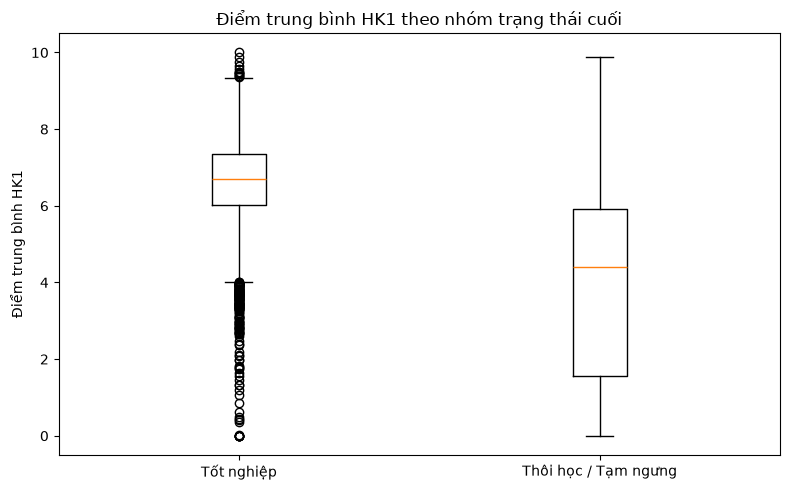

,count,mean,median,std
NhomKetQua,,,,
Thôi học / Tạm ngưng,9271,3.86,4.40,2.45
Tốt nghiệp,12207,6.65,6.69,1.05


In [36]:
status_df = eda.dropna(
    subset=["NhomKetQua", "DiemTBHocLuc_HK1"]
).copy()

groups = ["Tốt nghiệp", "Thôi học / Tạm ngưng"]
plot_data = [
    status_df.loc[
        status_df["NhomKetQua"] == group,
        "DiemTBHocLuc_HK1"
    ].values
    for group in groups
]

plt.figure(figsize=(8, 5))
plt.boxplot(plot_data, tick_labels=groups)
plt.title("Điểm trung bình HK1 theo nhóm trạng thái cuối")
plt.ylabel("Điểm trung bình HK1")
plt.tight_layout()
plt.show()

display(
    status_df.groupby("NhomKetQua")["DiemTBHocLuc_HK1"]
    .agg(["count", "mean", "median", "std"])
    .round(2)
)

,SoLuong,TyLeTotNghiep
CanhCaoHocVu_HK1,,
Không cảnh báo,17642,68.59
Có cảnh báo,3836,2.76


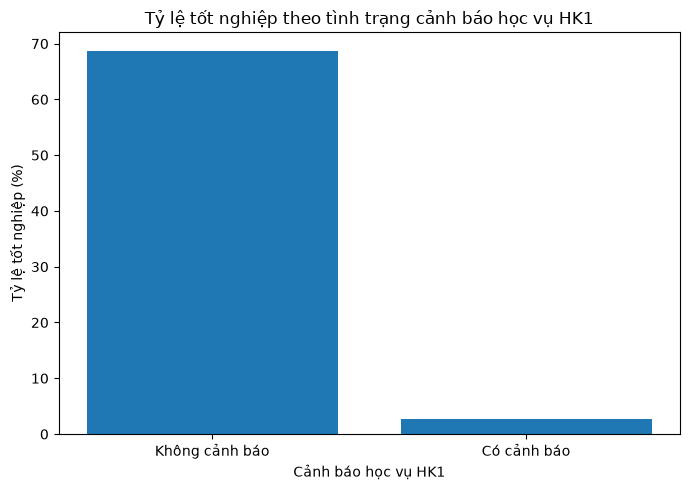

In [37]:
status_df = eda.dropna(
    subset=["NhomKetQua", "CanhCaoHocVu_HK1"]
).copy()

warning_summary = (
    status_df.groupby("CanhCaoHocVu_HK1")
    .agg(
        SoLuong=("NhomKetQua", "size"),
        TyLeTotNghiep=(
            "NhomKetQua",
            lambda s: (s == "Tốt nghiệp").mean() * 100
        )
    )
)

warning_summary.index = warning_summary.index.map({
    0: "Không cảnh báo",
    1: "Có cảnh báo"
})

display(warning_summary.round(2))

plt.figure(figsize=(7, 5))
plt.bar(
    warning_summary.index,
    warning_summary["TyLeTotNghiep"]
)
plt.title("Tỷ lệ tốt nghiệp theo tình trạng cảnh báo học vụ HK1")
plt.xlabel("Cảnh báo học vụ HK1")
plt.ylabel("Tỷ lệ tốt nghiệp (%)")
plt.tight_layout()
plt.show()

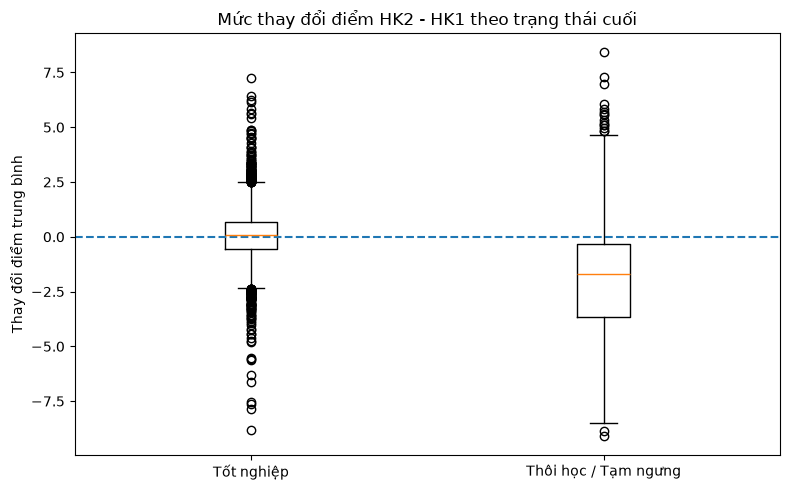

,count,mean,median,std
NhomKetQua,,,,
Thôi học / Tạm ngưng,7090,-2.00,-1.69,2.28
Tốt nghiệp,12203,0.07,0.06,1.00


In [38]:
status_change = eda.dropna(
    subset=[
        "NhomKetQua",
        "DiemTBHocLuc_HK1",
        "DiemTBHocLuc_HK2"
    ]
).copy()

status_change["ThayDoiDiem"] = (
    status_change["DiemTBHocLuc_HK2"]
    - status_change["DiemTBHocLuc_HK1"]
)

groups = ["Tốt nghiệp", "Thôi học / Tạm ngưng"]
plot_data = [
    status_change.loc[
        status_change["NhomKetQua"] == group,
        "ThayDoiDiem"
    ].values
    for group in groups
]

plt.figure(figsize=(8, 5))
plt.boxplot(plot_data, tick_labels=groups)
plt.axhline(0, linestyle="--")
plt.title("Mức thay đổi điểm HK2 - HK1 theo trạng thái cuối")
plt.ylabel("Thay đổi điểm trung bình")
plt.tight_layout()
plt.show()

display(
    status_change.groupby("NhomKetQua")["ThayDoiDiem"]
    .agg(["count", "mean", "median", "std"])
    .round(2)
)

In [50]:
# Phân bố mọi giá trị, bao gồm 0 và NaN
display(
    df["DiemHKDot1"]
    .value_counts(dropna=False)
    .sort_index()
    .rename_axis("DiemHKDot1")
    .to_frame("SoLuong")
)

print("Tỷ lệ NULL (%):", round(df["DiemHKDot1"].isna().mean() * 100, 2))
print("Tỷ lệ bằng 0 (%):", round(df["DiemHKDot1"].eq(0).mean() * 100, 2))

,SoLuong
DiemHKDot1,
0.0,323
1.0,1
10.0,3
11.0,1
16.0,1
...,...
97.0,22
98.0,15
99.0,11


Tỷ lệ NULL (%): 14.72
Tỷ lệ bằng 0 (%): 1.5


In [51]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

eda_hk = df.copy()

# Chuyển về dạng số nhưng không sửa df gốc
eda_hk["DiemHKDot1"] = pd.to_numeric(
    eda_hk["DiemHKDot1"], errors="coerce"
)

eda_hk["DiemTBHocLuc_HK1"] = pd.to_numeric(
    eda_hk["DiemTBHocLuc_HK1"], errors="coerce"
)

eda_hk["CanhCaoHocVu_HK1"] = pd.to_numeric(
    eda_hk["CanhCaoHocVu_HK1"], errors="coerce"
)

score = eda_hk["DiemHKDot1"]

# Tạo nhóm riêng cho giá trị âm, 0 và NULL
bins_score = pd.Series(index=eda_hk.index, dtype="object")
bins_score.loc[score.isna()] = "Thiếu dữ liệu"
bins_score.loc[score.eq(0)] = "0 điểm"
bins_score.loc[score.lt(0)] = "Điểm âm (kiểm tra)"

# Chia các điểm dương thành tối đa 4 nhóm theo tứ phân vị
positive = score[score > 0]

if positive.nunique() >= 2:
    q = min(4, positive.nunique())
    positive_bins = pd.qcut(
        positive,
        q=q,
        duplicates="drop"
    )

    bins_score.loc[positive.index] = positive_bins.astype(str)

    positive_bin_order = [
        str(interval)
        for interval in positive_bins.cat.categories
    ]

elif positive.nunique() == 1:
    bins_score.loc[positive.index] = "Điểm dương"
    positive_bin_order = ["Điểm dương"]

else:
    positive_bin_order = []

bin_order = (
    ["Điểm âm (kiểm tra)", "0 điểm"]
    + positive_bin_order
    + ["Thiếu dữ liệu"]
)

eda_hk["DiemHKDot1_Bin"] = pd.Categorical(
    bins_score,
    categories=bin_order,
    ordered=True
)

# Thứ tự nhóm trạng thái
eda_hk["NhomTrangThai"] = pd.to_numeric(
    eda_hk["NhomTrangThai"], errors="coerce"
)

target_labels = {
    1: "Đã tốt nghiệp",
    2: "Thôi học / Tạm ngưng"
}

eda_hk["NhomKetQua"] = eda_hk["NhomTrangThai"].map(target_labels)

display(
    eda_hk["DiemHKDot1_Bin"]
    .value_counts(sort=False)
    .to_frame("SoLuong")
)

,SoLuong
DiemHKDot1_Bin,
Điểm âm (kiểm tra),0
0 điểm,323
"(0.999, 55.0]",5250
"(55.0, 61.0]",4014
"(61.0, 70.0]",4931
"(70.0, 100.0]",3798
Thiếu dữ liệu,3162


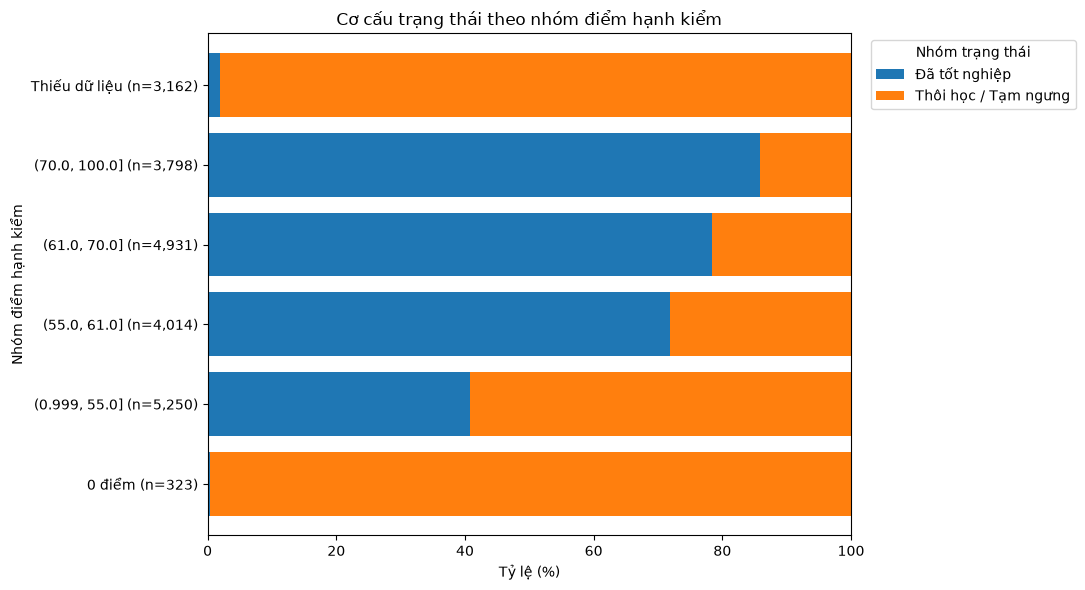

In [52]:
plot_df = eda_hk.dropna(
    subset=["NhomKetQua", "DiemHKDot1_Bin"]
).copy()

bin_counts = (
    plot_df["DiemHKDot1_Bin"]
    .value_counts(sort=False)
)

observed_bins = [
    b for b in bin_order
    if bin_counts.get(b, 0) > 0
]

status_order = ["Đã tốt nghiệp", "Thôi học / Tạm ngưng"]

status_pct = pd.crosstab(
    plot_df["DiemHKDot1_Bin"],
    plot_df["NhomKetQua"],
    normalize="index"
).mul(100)

status_pct = status_pct.reindex(
    index=observed_bins,
    columns=status_order,
    fill_value=0
)

# Thêm số lượng quan sát vào nhãn
status_pct.index = [
    f"{b} (n={bin_counts[b]:,})"
    for b in observed_bins
]

ax = status_pct.plot(
    kind="barh",
    stacked=True,
    figsize=(11, 6),
    width=0.8
)

ax.set_title("Cơ cấu trạng thái theo nhóm điểm hạnh kiểm")
ax.set_xlabel("Tỷ lệ (%)")
ax.set_ylabel("Nhóm điểm hạnh kiểm")
ax.set_xlim(0, 100)
ax.legend(
    title="Nhóm trạng thái",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

plt.tight_layout()
plt.show()

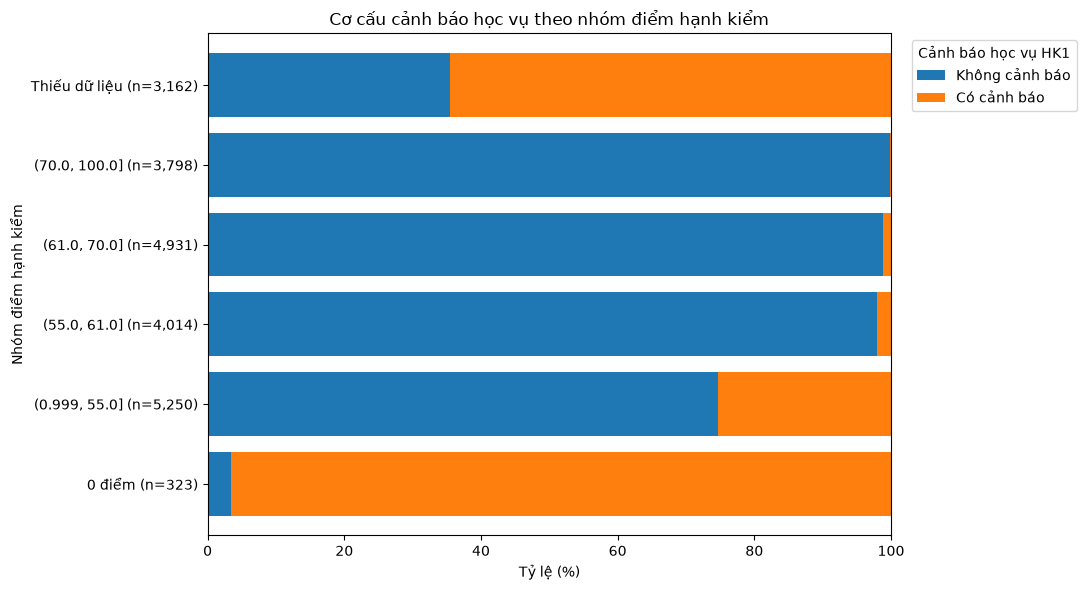

In [54]:
warning_df = eda_hk.dropna(
    subset=["DiemHKDot1_Bin", "CanhCaoHocVu_HK1"]
).copy()

warning_df = warning_df[
    warning_df["CanhCaoHocVu_HK1"].isin([0, 1])
]

warning_df["TrangThaiCanhCao"] = (
    warning_df["CanhCaoHocVu_HK1"]
    .map({
        0: "Không cảnh báo",
        1: "Có cảnh báo"
    })
)

warning_counts = (
    warning_df["DiemHKDot1_Bin"]
    .value_counts(sort=False)
)

observed_warning_bins = [
    b for b in bin_order
    if warning_counts.get(b, 0) > 0
]

warning_order = ["Không cảnh báo", "Có cảnh báo"]

warning_pct = pd.crosstab(
    warning_df["DiemHKDot1_Bin"],
    warning_df["TrangThaiCanhCao"],
    normalize="index"
).mul(100)

warning_pct = warning_pct.reindex(
    index=observed_warning_bins,
    columns=warning_order,
    fill_value=0
)

warning_pct.index = [
    f"{b} (n={warning_counts[b]:,})"
    for b in observed_warning_bins
]

ax = warning_pct.plot(
    kind="barh",
    stacked=True,
    figsize=(11, 6),
    width=0.8
)

ax.set_title("Cơ cấu cảnh báo học vụ theo nhóm điểm hạnh kiểm")
ax.set_xlabel("Tỷ lệ (%)")
ax.set_ylabel("Nhóm điểm hạnh kiểm")
ax.set_xlim(0, 100)
ax.legend(
    title="Cảnh báo học vụ HK1",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

plt.tight_layout()
plt.show()

Số điểm được vẽ: 18316
Số dòng DiemHKDot1 = 0: 323
Số dòng DiemHKDot1 bị NULL: 3162


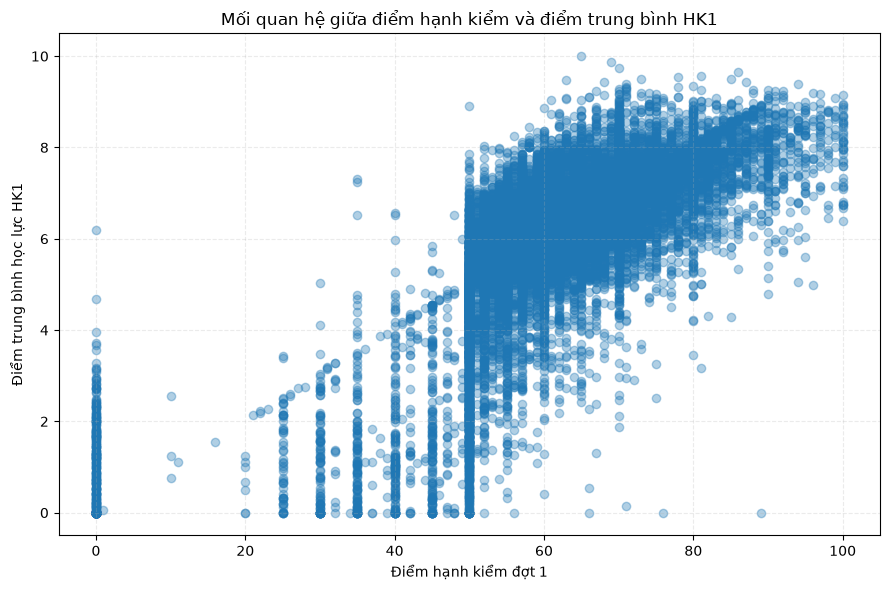

In [55]:
# Giữ cả điểm hạnh kiểm bằng 0; chỉ bỏ NULL khi vẽ scatterplot
scatter_df = eda_hk.dropna(
    subset=["DiemHKDot1", "DiemTBHocLuc_HK1"]
).copy()

print("Số điểm được vẽ:", len(scatter_df))
print("Số dòng DiemHKDot1 = 0:", (scatter_df["DiemHKDot1"] == 0).sum())
print("Số dòng DiemHKDot1 bị NULL:", eda_hk["DiemHKDot1"].isna().sum())

plt.figure(figsize=(9, 6))

plt.scatter(
    scatter_df["DiemHKDot1"],
    scatter_df["DiemTBHocLuc_HK1"],
    alpha=0.35
)

plt.title("Mối quan hệ giữa điểm hạnh kiểm và điểm trung bình HK1")
plt.xlabel("Điểm hạnh kiểm đợt 1")
plt.ylabel("Điểm trung bình học lực HK1")
plt.grid(True, linestyle="--", alpha=0.25)
plt.tight_layout()
plt.show()

In [ ]:
#
#
#

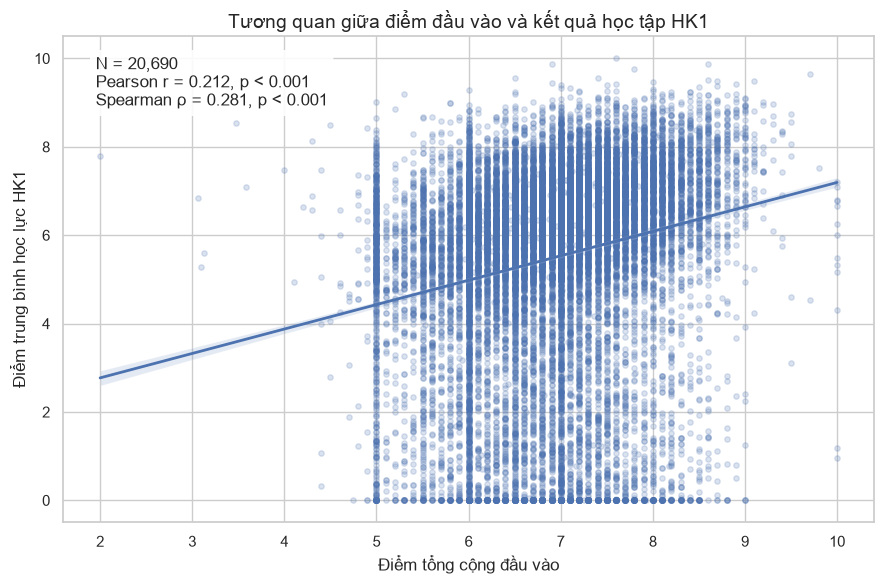


--- Tương quan giữa điểm đầu vào và kết quả học tập HK1 ---
Số cặp quan sát: 20,690
Pearson: r = 0.2122, p = 2.47459e-209
Spearman: rho = 0.2814, p = 0


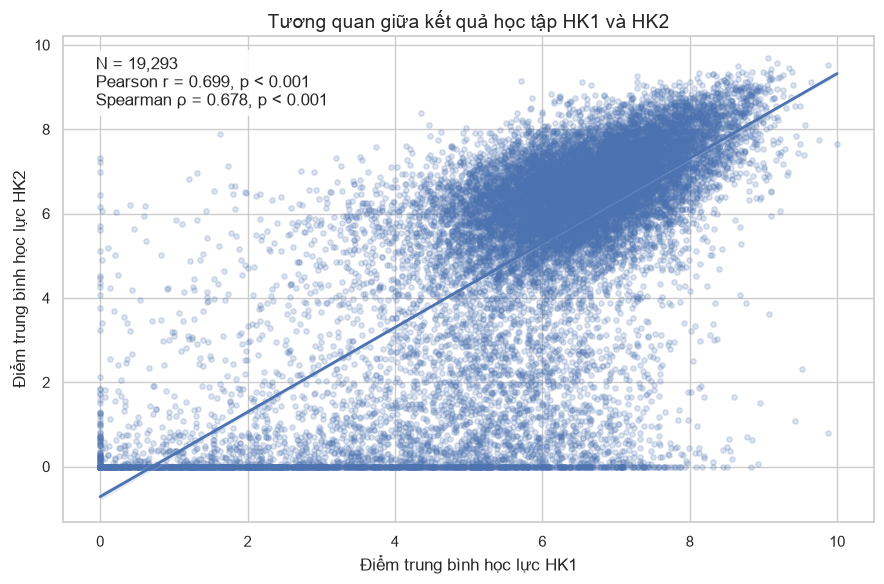


--- Tương quan giữa kết quả học tập HK1 và HK2 ---
Số cặp quan sát: 19,293
Pearson: r = 0.6988, p = 0
Spearman: rho = 0.6778, p = 0


In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import pearsonr, spearmanr

sns.set_theme(style="whitegrid")


def phan_tich_tuong_quan(data, x_col, y_col, x_label, y_label, title):
    temp = data[[x_col, y_col]].copy()

    # Chuyển sang dạng số và chỉ giữ các cặp quan sát hợp lệ
    for col in [x_col, y_col]:
        temp[col] = pd.to_numeric(temp[col], errors="coerce")

    temp = temp.replace([np.inf, -np.inf], np.nan).dropna()

    if len(temp) < 3:
        print(f"Không đủ dữ liệu để kiểm định: {title}")
        return

    x = temp[x_col]
    y = temp[y_col]

    # Kiểm định tương quan
    r_pearson, p_pearson = pearsonr(x, y)
    r_spearman, p_spearman = spearmanr(x, y)

    # Vẽ biểu đồ
    plt.figure(figsize=(9, 6))
    sns.regplot(
        data=temp,
        x=x_col,
        y=y_col,
        scatter_kws={"alpha": 0.2, "s": 15},
        line_kws={"linewidth": 2},
        ci=95
    )

    plt.title(title, fontsize=14)
    plt.xlabel(x_label)
    plt.ylabel(y_label)

    def format_p(p):
        return "< 0.001" if p < 0.001 else f"= {p:.3f}"

    thong_tin = (
        f"N = {len(temp):,}\n"
        f"Pearson r = {r_pearson:.3f}, p {format_p(p_pearson)}\n"
        f"Spearman ρ = {r_spearman:.3f}, p {format_p(p_spearman)}"
    )

    plt.text(
        0.04, 0.96, thong_tin,
        transform=plt.gca().transAxes,
        va="top",
        bbox=dict(boxstyle="round", facecolor="white", alpha=0.9)
    )

    plt.tight_layout()
    plt.show()

    print(f"\n--- {title} ---")
    print(f"Số cặp quan sát: {len(temp):,}")
    print(f"Pearson: r = {r_pearson:.4f}, p = {p_pearson:.6g}")
    print(f"Spearman: rho = {r_spearman:.4f}, p = {p_spearman:.6g}")


# Câu hỏi 1: Điểm đầu vào và kết quả học tập HK1
phan_tich_tuong_quan(
    data=df,
    x_col="DiemTongCong",
    y_col="DiemTBHocLuc_HK1",
    x_label="Điểm tổng cộng đầu vào",
    y_label="Điểm trung bình học lực HK1",
    title="Tương quan giữa điểm đầu vào và kết quả học tập HK1"
)

# Câu hỏi 2: Kết quả học tập HK1 và HK2
phan_tich_tuong_quan(
    data=df,
    x_col="DiemTBHocLuc_HK1",
    y_col="DiemTBHocLuc_HK2",
    x_label="Điểm trung bình học lực HK1",
    y_label="Điểm trung bình học lực HK2",
    title="Tương quan giữa kết quả học tập HK1 và HK2"
)